# So sánh tính khả thi gán nhãn giữa ba nguồn

Notebook so sánh Seafar, Hohai và Southampton bằng loader/configuration và summary của `ml.labeling`. Thống kê mô tả không được dùng để tạo lớp cân bằng; các nguồn có quy mô vật lý và chất lượng metadata khác nhau.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/config.yaml").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/config.yaml").is_file())
sys.path.insert(0, str(REPO_ROOT))
from ml.labeling.feasibility import load_eligible_windows
DATASETS = ("seafar", "hohai", "southampton")
SUMMARY = json.loads((REPO_ROOT / "ml/reports/labeling/labeling_summary.json").read_text(encoding="utf-8"))
WINDOWS = load_eligible_windows(REPO_ROOT / "ml/data/features", DATASETS)

## Khả năng cửa sổ và session

Số cửa sổ biểu thị endpoint có đủ lịch sử, không phải số quan sát độc lập. Dữ liệu Southampton chỉ có một run đủ 180 giây; Hohai sheets và Southampton runs được giữ riêng.

In [2]:
comparison = []
for dataset, frame in WINDOWS.items():
    item = SUMMARY["datasets"][dataset]
    comparison.append({"Nguồn": dataset, "Feature rows 60 giây": item["feature_candidate_rows_60s"],
        "Cửa sổ 180 giây đủ 23": len(frame), "Session hỗ trợ": frame.session_id.nunique(),
        "Segment": frame.segment_id.nunique(), "Nhãn xác minh": 0, "Human review": 0,
        "Median độ lệch chuẩn Roll 60s (°)": frame.roll_std_60.median(),
        "P95 độ lệch chuẩn Roll 60s (°)": frame.roll_std_60.quantile(.95)})
display(pd.DataFrame(comparison).set_index("Nguồn"))

,Feature rows 60 giây,Cửa sổ 180 giây đủ 23,Session hỗ trợ,Segment,Nhãn xác minh,Human review,Median độ lệch chuẩn Roll 60s (°),P95 độ lệch chuẩn Roll 60s (°)
Nguồn,,,,,,,,
seafar,1384,1318,1,4,0,0,0.095261,0.285095
hohai,1764,1512,21,1,0,0,0.340095,0.533077
southampton,277,34,1,1,0,0,0.017848,0.106546


## Điều kiện nguồn và giới hạn so sánh

- **Seafar:** một session tàu thật; Roll có offset nền và segment bị chia do timestamp quality.
- **Hohai:** 21 session mô hình thử nghiệm; 50 Hz từ metadata tài liệu, không có timestamp/gyro trực tiếp.
- **Southampton:** 47 model-scale runs; wave metadata là provenance, chỉ một run đủ 180 giây.

Không so sánh các phân bố như cùng một quần thể vật lý, không suy lớp từ wave amplitude và không coi source identity là feature.

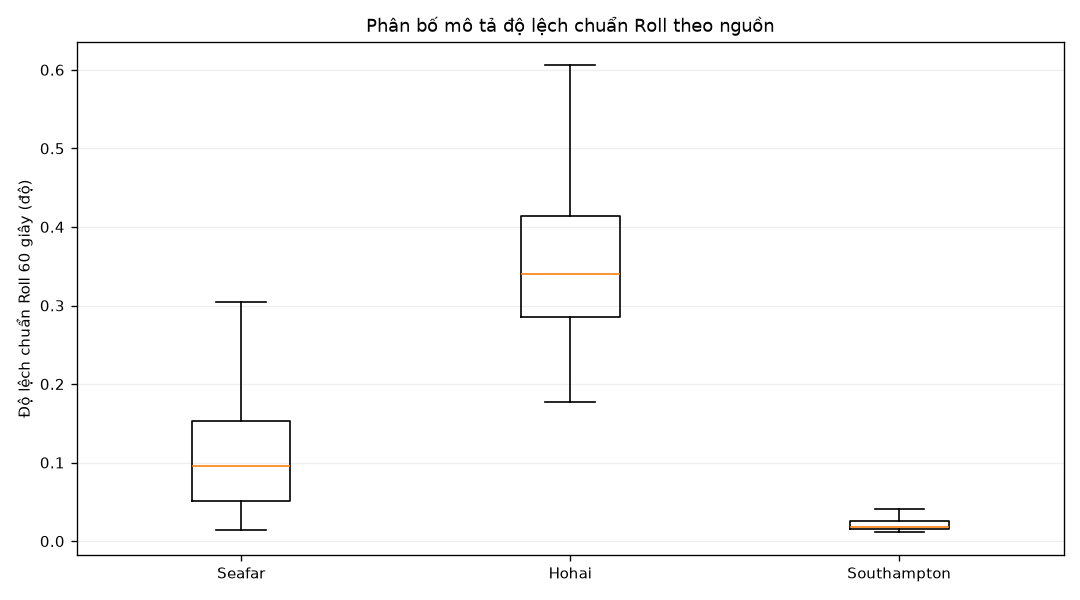

,Lớp,Nhãn proxy,Session có bằng chứng xác minh,Trạng thái
0,NORMAL,0,0,Chưa đủ căn cứ
1,HIGH_ROLL,0,0,Chưa đủ căn cứ
2,PERSISTENT_OFFSET,0,0,Chưa đủ căn cứ
3,AMPLITUDE_GROWTH,0,0,Chưa đủ căn cứ


In [3]:
display(Image(filename=str(REPO_ROOT / "ml/data/labels/diagnostics/comparison_roll_std.png")))
classes = pd.DataFrame([{"Lớp": label, "Nhãn proxy": 0, "Session có bằng chứng xác minh": 0, "Trạng thái": "Chưa đủ căn cứ"}
                        for label in ("NORMAL", "HIGH_ROLL", "PERSISTENT_OFFSET", "AMPLITUDE_GROWTH")])
display(classes)

## Kết luận feasibility và bước cần thiết

Hiện không có nhãn external reference, reviewer decisions hoặc operating envelope được phê duyệt. Bốn lớp do đó đều chưa được xác lập; đây không phải kết luận rằng các trạng thái vật lý không xảy ra. Bước tiếp theo là thu thập event/operating-envelope độc lập, xác minh datum/trục/cảm biến, sau đó thiết kế ngưỡng riêng phạm vi có cơ sở và tiến hành review mù theo session. Không nên huấn luyện Random Forest từ proxy labels trước khi giải quyết circular validation.

### Giải thích kỹ thuật phục vụ vấn đáp

**Em đã làm gì?** So sánh counts/session và thống kê từ feature tables với source evidence. **Vì sao?** Đánh giá coverage thật mà không trộn run. **Phương pháp?** Ghép metadata theo window ID và lấy các hàng đủ 23 feature angle-only. **Kết quả?** 1.318 Seafar, 1.512 Hohai, 34 Southampton cửa sổ; không có nhãn xác minh. **Nếu xem count là số độc lập?** Sẽ phóng đại bằng chứng do stride 10 giây trên cửa sổ 180 giây. **Giới hạn?** Khác biệt full-scale/model-scale và thiếu nhãn độc lập ngăn diễn giải hazard.